In [1]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("community-datasets/roman_urdu")
print(ds)

# The labels are stored as numbers, so get their names from the dataset itself
names = ds["train"].features["sentiment"].names
print(names)

df = ds["train"].to_pandas()
df["label"] = df["sentiment"].map(lambda i: names[i])
df.head()

README.md:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.06MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/20229 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'sentiment'],
        num_rows: 20229
    })
})
['Positive', 'Negative', 'Neutral']


,sentence,sentiment,label
0,Sai kha ya her kisi kay bus ki bat nhi hai lak...,0,Positive
1,sahi bt h,0,Positive
2,"Kya bt hai,",0,Positive
3,Wah je wah,0,Positive
4,Are wha kaya bat hai,0,Positive


In [2]:
df["sentence"] = df["sentence"].fillna("").str.strip()
print("Empty sentences:", (df["sentence"] == "").sum())

Empty sentences: 113


In [3]:
rows_start = len(df)
d = df[df["sentence"] != ""].copy()
after_empty = len(d)

# A lowercase key catches "Nice" and "nice" as the same sentence
d["key"] = d["sentence"].str.lower()

# Remove sentences that appear with conflicting labels (we cannot know which is right)
labels_per_key = d.groupby("key")["label"].transform("nunique")
d = d[labels_per_key == 1]
after_conflicts = len(d)

d = d.drop_duplicates(subset="key")
after_dups = len(d)

print(rows_start, after_empty, after_conflicts, after_dups)
d["label"].value_counts(normalize=True).round(3)

20229 20116 20010 19495


,proportion
label,
Neutral,0.433
Positive,0.298
Negative,0.268


In [4]:
from sklearn.model_selection import train_test_split

d["text"] = d["key"]    # lowercase text for the baseline
train_df, temp_df = train_test_split(d, test_size=0.2, stratify=d["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=42)
print(len(train_df), len(val_df), len(test_df))

15596 1949 1950


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent").fit(train_df["text"], train_df["label"])
pred = dummy.predict(val_df["text"])
print("Dummy accuracy:", round(accuracy_score(val_df["label"], pred), 3))
print("Dummy macro-F1:", round(f1_score(val_df["label"], pred, average="macro"), 3))

Dummy accuracy: 0.434
Dummy macro-F1: 0.202


In [6]:
from sklearn.pipeline import make_pipeline, make_union
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

features = make_union(
    TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True),
)
tfidf_lr = make_pipeline(features, LogisticRegression(max_iter=1000, C=3))
tfidf_lr.fit(train_df["text"], train_df["label"])

pred = tfidf_lr.predict(val_df["text"])
print(classification_report(val_df["label"], pred, digits=3))

              precision    recall  f1-score   support

    Negative      0.655     0.602     0.627       523
     Neutral      0.682     0.751     0.715       845
    Positive      0.702     0.649     0.674       581

    accuracy                          0.681      1949
   macro avg      0.680     0.668     0.672      1949
weighted avg      0.681     0.681     0.679      1949



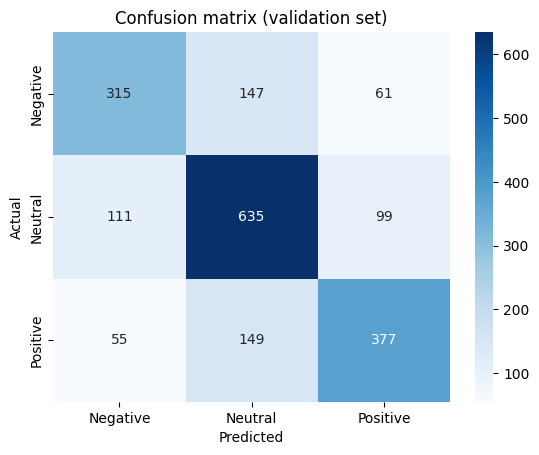

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

order = ["Negative", "Neutral", "Positive"]
cm = confusion_matrix(val_df["label"], pred, labels=order)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=order, yticklabels=order)
plt.title("Confusion matrix (validation set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()